In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

In [5]:
from io import StringIO
from pathlib import Path

IRIS_CSV = """sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa
4.9,3.1,1.5,0.1,setosa
5.4,3.7,1.5,0.2,setosa
4.8,3.4,1.6,0.2,setosa
4.8,3.0,1.4,0.1,setosa
4.3,3.0,1.1,0.1,setosa
5.8,4.0,1.2,0.2,setosa
5.7,4.4,1.5,0.4,setosa
5.4,3.9,1.3,0.4,setosa
5.1,3.5,1.4,0.3,setosa
5.7,3.8,1.7,0.3,setosa
5.1,3.8,1.5,0.3,setosa
5.4,3.4,1.7,0.2,setosa
5.1,3.7,1.5,0.4,setosa
4.6,3.6,1.0,0.2,setosa
5.1,3.3,1.7,0.5,setosa
4.8,3.4,1.9,0.2,setosa
5.0,3.0,1.6,0.2,setosa
5.0,3.4,1.6,0.4,setosa
5.2,3.5,1.5,0.2,setosa
5.2,3.4,1.4,0.2,setosa
4.7,3.2,1.6,0.2,setosa
4.8,3.1,1.6,0.2,setosa
5.4,3.4,1.5,0.4,setosa
5.2,4.1,1.5,0.1,setosa
5.5,4.2,1.4,0.2,setosa
4.9,3.1,1.5,0.2,setosa
5.0,3.2,1.2,0.2,setosa
5.5,3.5,1.3,0.2,setosa
4.9,3.6,1.4,0.1,setosa
4.4,3.0,1.3,0.2,setosa
5.1,3.4,1.5,0.2,setosa
5.0,3.5,1.3,0.3,setosa
4.5,2.3,1.3,0.3,setosa
4.4,3.2,1.3,0.2,setosa
5.0,3.5,1.6,0.6,setosa
5.1,3.8,1.9,0.4,setosa
4.8,3.0,1.4,0.3,setosa
5.1,3.8,1.6,0.2,setosa
4.6,3.2,1.4,0.2,setosa
5.3,3.7,1.5,0.2,setosa
5.0,3.3,1.4,0.2,setosa
7.0,3.2,4.7,1.4,versicolor
6.4,3.2,4.5,1.5,versicolor
6.9,3.1,4.9,1.5,versicolor
5.5,2.3,4.0,1.3,versicolor
6.5,2.8,4.6,1.5,versicolor
5.7,2.8,4.5,1.3,versicolor
6.3,3.3,4.7,1.6,versicolor
4.9,2.4,3.3,1.0,versicolor
6.6,2.9,4.6,1.3,versicolor
5.2,2.7,3.9,1.4,versicolor
5.0,2.0,3.5,1.0,versicolor
5.9,3.0,4.2,1.5,versicolor
6.0,2.2,4.0,1.0,versicolor
6.1,2.9,4.7,1.4,versicolor
5.6,2.9,3.6,1.3,versicolor
6.7,3.1,4.4,1.4,versicolor
5.6,3.0,4.5,1.5,versicolor
5.8,2.7,4.1,1.0,versicolor
6.2,2.2,4.5,1.5,versicolor
5.6,2.5,3.9,1.1,versicolor
5.9,3.2,4.8,1.8,versicolor
6.1,2.8,4.0,1.3,versicolor
6.3,2.5,4.9,1.5,versicolor
6.1,2.8,4.7,1.2,versicolor
6.4,2.9,4.3,1.3,versicolor
6.6,3.0,4.4,1.4,versicolor
6.8,2.8,4.8,1.4,versicolor
6.7,3.0,5.0,1.7,versicolor
6.0,2.9,4.5,1.5,versicolor
5.7,2.6,3.5,1.0,versicolor
5.5,2.4,3.8,1.1,versicolor
5.5,2.4,3.7,1.0,versicolor
5.8,2.7,3.9,1.2,versicolor
6.0,2.7,5.1,1.6,versicolor
5.4,3.0,4.5,1.5,versicolor
6.0,3.4,4.5,1.6,versicolor
6.7,3.1,4.7,1.5,versicolor
6.3,2.3,4.4,1.3,versicolor
5.6,3.0,4.1,1.3,versicolor
5.5,2.5,4.0,1.3,versicolor
5.5,2.6,4.4,1.2,versicolor
6.1,3.0,4.6,1.4,versicolor
5.8,2.6,4.0,1.2,versicolor
5.0,2.3,3.3,1.0,versicolor
5.6,2.7,4.2,1.3,versicolor
5.7,3.0,4.2,1.2,versicolor
5.7,2.9,4.2,1.3,versicolor
6.2,2.9,4.3,1.3,versicolor
5.1,2.5,3.0,1.1,versicolor
5.7,2.8,4.1,1.3,versicolor
6.3,3.3,6.0,2.5,virginica
5.8,2.7,5.1,1.9,virginica
7.1,3.0,5.9,2.1,virginica
6.3,2.9,5.6,1.8,virginica
6.5,3.0,5.8,2.2,virginica
7.6,3.0,6.6,2.1,virginica
4.9,2.5,4.5,1.7,virginica
7.3,2.9,6.3,1.8,virginica
6.7,2.5,5.8,1.8,virginica
7.2,3.6,6.1,2.5,virginica
6.5,3.2,5.1,2.0,virginica
6.4,2.7,5.3,1.9,virginica
6.8,3.0,5.5,2.1,virginica
5.7,2.5,5.0,2.0,virginica
5.8,2.8,5.1,2.4,virginica
6.4,3.2,5.3,2.3,virginica
6.5,3.0,5.5,1.8,virginica
7.7,3.8,6.7,2.2,virginica
7.7,2.6,6.9,2.3,virginica
6.0,2.2,5.0,1.5,virginica
6.9,3.2,5.7,2.3,virginica
5.6,2.8,4.9,2.0,virginica
7.7,2.8,6.7,2.0,virginica
6.3,2.7,4.9,1.8,virginica
6.7,3.3,5.7,2.1,virginica
7.2,3.2,6.0,1.8,virginica
6.2,2.8,4.8,1.8,virginica
6.1,3.0,4.9,1.8,virginica
6.4,2.8,5.6,2.1,virginica
7.2,3.0,5.8,1.6,virginica
7.4,2.8,6.1,1.9,virginica
7.9,3.8,6.4,2.0,virginica
6.4,2.8,5.6,2.2,virginica
6.3,2.8,5.1,1.5,virginica
6.1,2.6,5.6,1.4,virginica
7.7,3.0,6.1,2.3,virginica
6.3,3.4,5.6,2.4,virginica
6.4,3.1,5.5,1.8,virginica
6.0,3.0,4.8,1.8,virginica
6.9,3.1,5.4,2.1,virginica
6.7,3.1,5.6,2.4,virginica
6.9,3.1,5.1,2.3,virginica
5.8,2.7,5.1,1.9,virginica
6.8,3.2,5.9,2.3,virginica
6.7,3.3,5.7,2.5,virginica
6.7,3.0,5.2,2.3,virginica
6.3,2.5,5.0,1.9,virginica
6.5,3.0,5.2,2.0,virginica
6.2,3.4,5.4,2.3,virginica
5.9,3.0,5.1,1.8,virginica
"""

if Path("iris.csv").exists():
    df = pd.read_csv("iris.csv")
    print("Loaded iris.csv from", Path("iris.csv").resolve())
else:
    df = pd.read_csv(StringIO(IRIS_CSV))
    print("iris.csv not found in", Path.cwd(), "- using the embedded dataset")

print("Shape:", df.shape)
display(df.head())
print("\nMissing values per column:")
print(df.isna().sum())
print("\nClass distribution:")
print(df["species"].value_counts())
display(df.describe().T)

iris.csv not found in C:\Users\Aspire - using the embedded dataset
Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


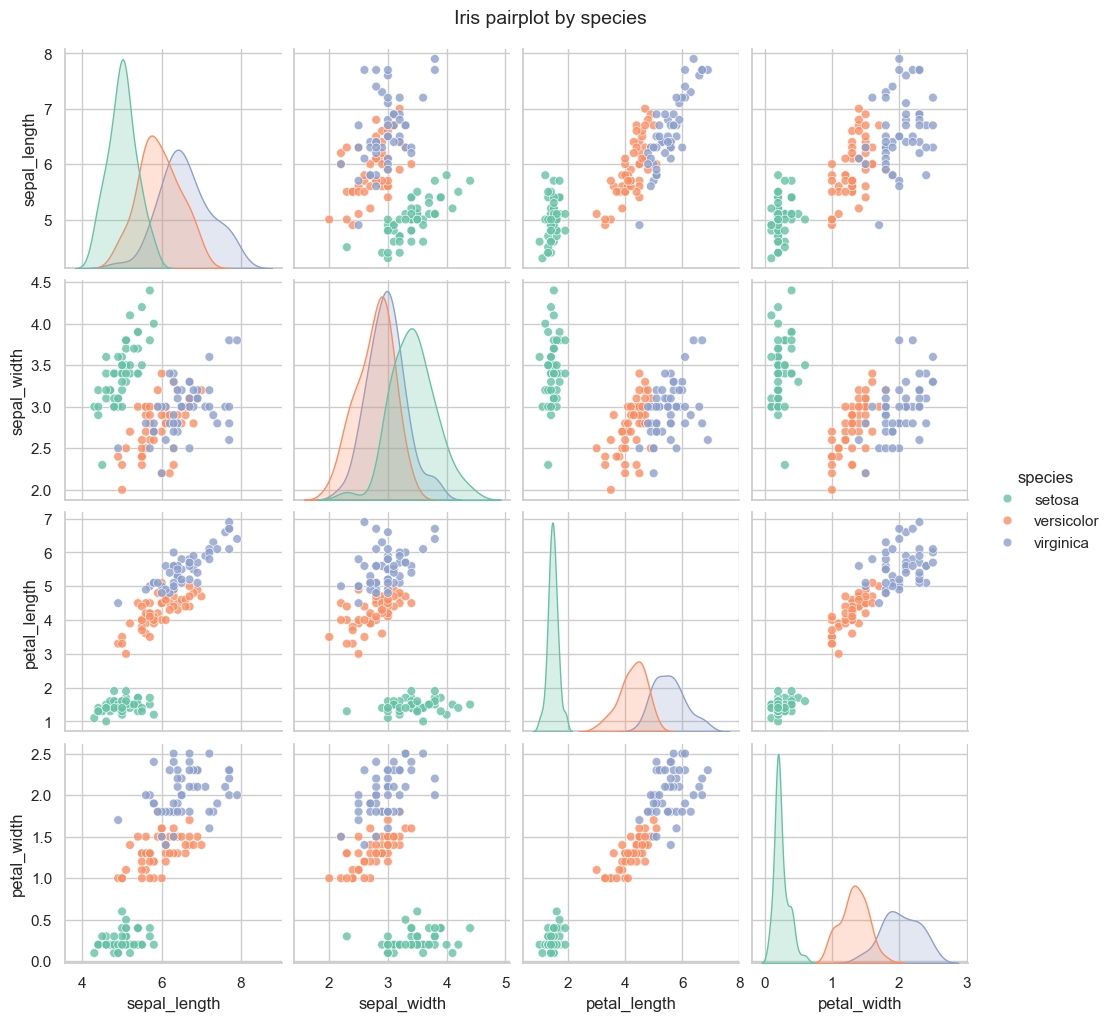

In [6]:
g = sns.pairplot(df, hue="species", diag_kind="kde", palette="Set2",
                 plot_kws={"alpha": 0.8, "s": 40})
g.figure.suptitle("Iris pairplot by species", y=1.02, fontsize=14)
plt.show()

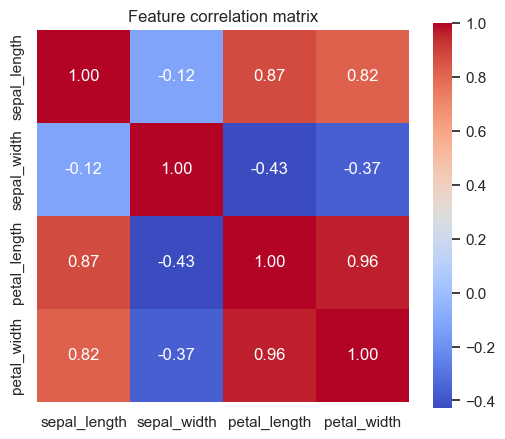

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Feature correlation matrix")
plt.show()

In [8]:
X = df.drop(columns="species")
y = df["species"]
feature_names = X.columns.tolist()
class_names = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   
X_test_s = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("\nTrain means after scaling (~0):", np.round(X_train_s.mean(axis=0), 3))
print("Train stds after scaling  (~1):", np.round(X_train_s.std(axis=0), 3))

Train: 120 samples | Test: 30 samples

Train means after scaling (~0): [-0.  0.  0.  0.]
Train stds after scaling  (~1): [1. 1. 1. 1.]


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

preds = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds[name] = model.predict(X_test_s)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree


,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


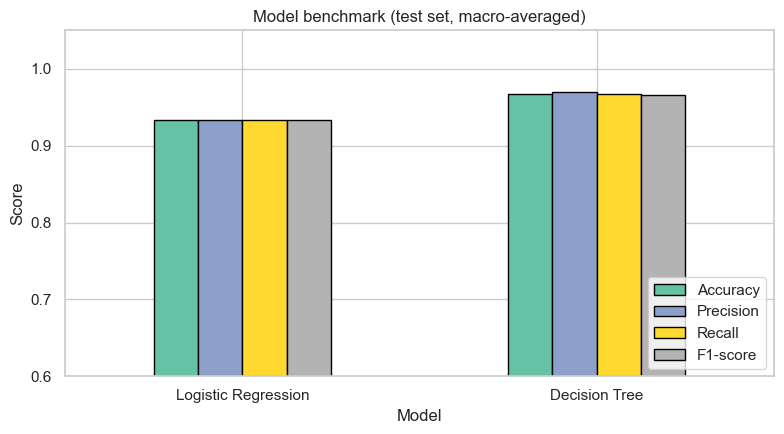

In [10]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score":  f1_score(y_test, y_pred, average="macro", zero_division=0),
    })
results = pd.DataFrame(rows).set_index("Model")
display(results.style.format("{:.4f}").background_gradient(cmap="Greens", axis=None))

ax = results.plot(kind="bar", figsize=(8, 4.5), rot=0, colormap="Set2", edgecolor="black")
ax.set_ylim(0.6, 1.05)
ax.set_title("Model benchmark (test set, macro-averaged)")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
for name, y_pred in preds.items():
    print("=" * 60)
    print(f"Classification report: {name}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3, zero_division=0))

Classification report: Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Classification report: Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



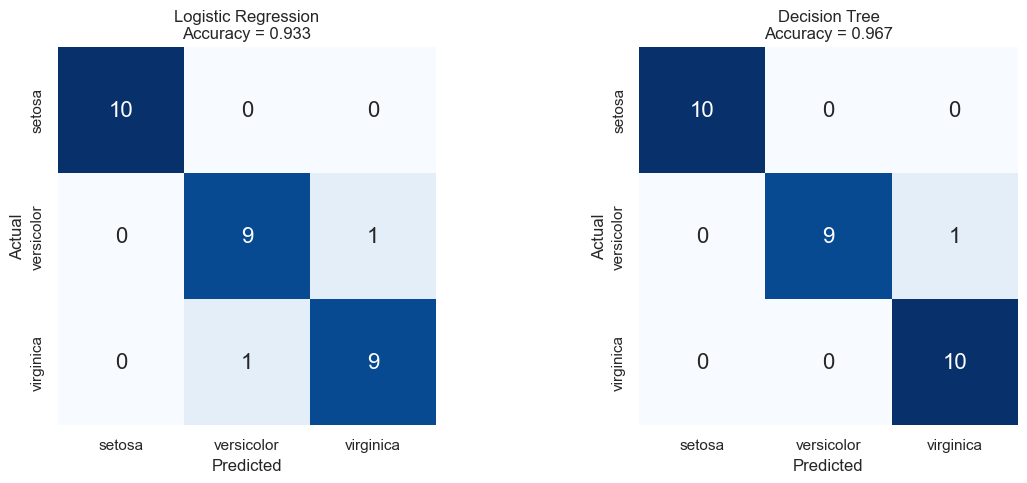

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 16}, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

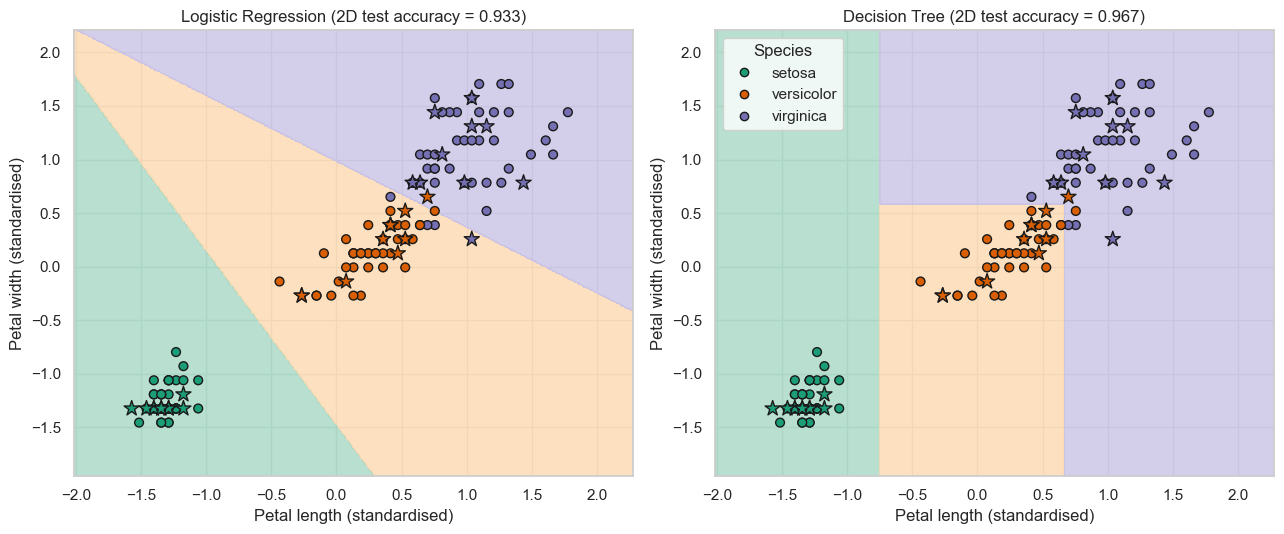

In [13]:
feat_2d = ["petal_length", "petal_width"]
X2_train, X2_test = X_train[feat_2d], X_test[feat_2d]

scaler_2d = StandardScaler()
X2_train_s = scaler_2d.fit_transform(X2_train)
X2_test_s = scaler_2d.transform(X2_test)

label_map = {c: i for i, c in enumerate(class_names)}
y_train_n = y_train.map(label_map).values
y_test_n = y_test.map(label_map).values

models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

cmap_bg = ListedColormap(["#a6d8c4", "#fdd9b0", "#c9c4e6"])
cmap_pts = ListedColormap(["#1b9e77", "#d95f02", "#7570b3"])

pad = 0.5
x_min, x_max = X2_train_s[:, 0].min() - pad, X2_train_s[:, 0].max() + pad
y_min, y_max = X2_train_s[:, 1].min() - pad, X2_train_s[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, model) in zip(axes, models_2d.items()):
    model.fit(X2_train_s, y_train_n)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.8)
    ax.scatter(X2_train_s[:, 0], X2_train_s[:, 1], c=y_train_n, cmap=cmap_pts,
               edgecolor="k", s=40, label="Train")
    ax.scatter(X2_test_s[:, 0], X2_test_s[:, 1], c=y_test_n, cmap=cmap_pts,
               edgecolor="k", s=130, marker="*", label="Test")
    acc = accuracy_score(y_test_n, model.predict(X2_test_s))
    ax.set_title(f"{name} (2D test accuracy = {acc:.3f})")
    ax.set_xlabel("Petal length (standardised)")
    ax.set_ylabel("Petal width (standardised)")

handles = [plt.Line2D([], [], marker="o", ls="", color=cmap_pts(i), markeredgecolor="k", label=c)
           for i, c in enumerate(class_names)]
axes[1].legend(handles=handles, title="Species", loc="upper left")
plt.tight_layout()
plt.show()

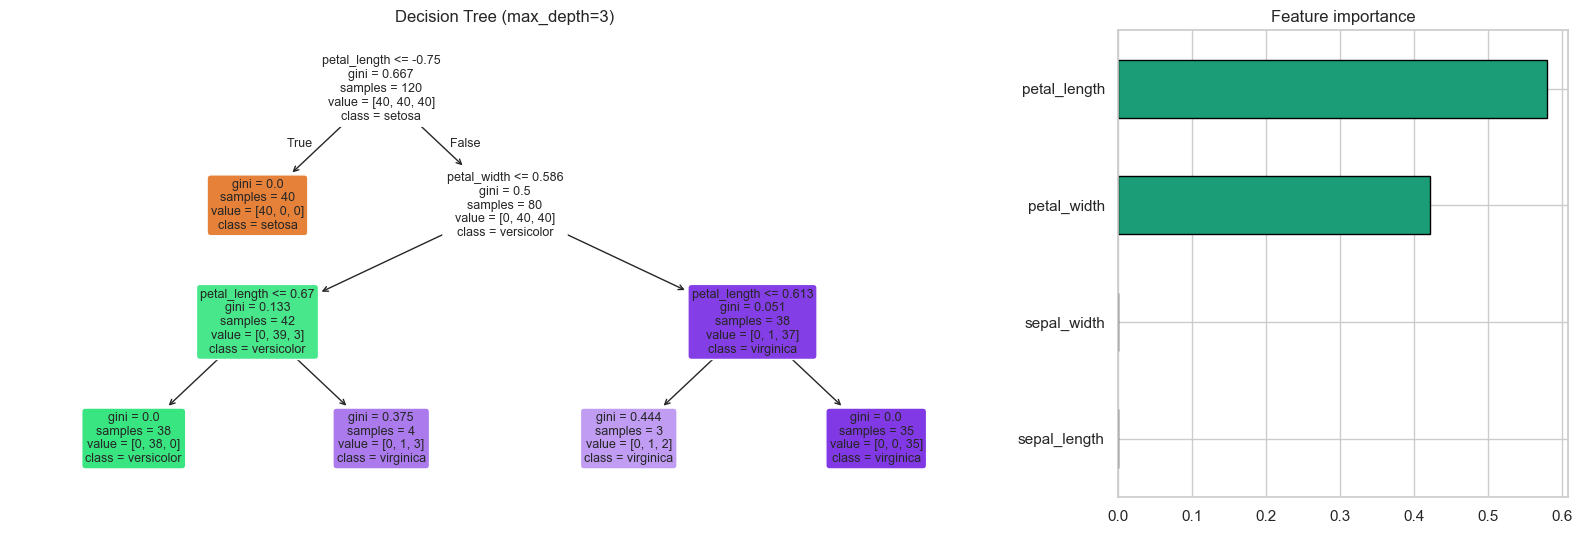

In [14]:
dt = models["Decision Tree"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(dt, feature_names=feature_names, class_names=class_names,
          filled=True, rounded=True, fontsize=9, ax=axes[0])
axes[0].set_title("Decision Tree (max_depth=3)")

imp = pd.Series(dt.feature_importances_, index=feature_names).sort_values()
imp.plot(kind="barh", color="#1b9e77", edgecolor="black", ax=axes[1])
axes[1].set_title("Feature importance")
plt.tight_layout()
plt.show()